# Laplace (última capa)

Distribución gaussiana sobre los pesos de la última capa de SEED (`classifier.logits`, 128 → 1), ajustada con los registros crudos de train, una predicción de SEED por punto, la verosimilitud dividida por el tiempo de autocorrelación τ (evidencia efectiva N/τ) y el prior elegido por grid search en validación. 30 muestras por registro. No reentrena SEED.


**Datos.** Evaluaciones 0, 1 y 2, cinco folds de test cada una (15 folds en total). Se leen los `test_predictions.npz` ya guardados: el notebook no entrena ni vuelve a inferir. Todo se calcula sobre los timesteps válidos.

**Cómo leer las tablas.** Cada tabla muestra *media ± desviación estándar* entre folds para cada evaluación (0, 1 y 2) y el promedio de las tres (los 15 folds juntos). Los gráficos tienen cuatro paneles con las mismas cuatro vistas.

**Definiciones que se repiten**

- *Cerca de eventos*: ±1 s alrededor de un huso real o predicho. Es donde ocurren los errores; el ~92% restante es fondo fácil que infla los AUROC.
- *Azar*: 0.5 para un AUROC; para un AUPRC, la proporción de positivos (tasa de error o proporción de FP/FN).
- *Aleatoria* = entropía esperada (ambigüedad de la señal); *epistémica* = MI (desacuerdo entre muestras del modelo); *total* = entropía predictiva = aleatoria + MI.
- *SEED H(p)*: la incertidumbre del SEED original sobre los mismos timesteps o eventos, como referencia.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import report

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

METHOD = 'Laplace'
REFRESH = False  # True recalcula desde los NPZ (varios minutos)
results = report.method_results(METHOD, refresh=REFRESH)
metrics = results['metrics']

Laplace: evaluación 0 lista
Laplace: evaluación 1 lista
Laplace: evaluación 2 lista


## 1. Detección y calibración

F1, precisión y recall por evento (IoU ≥ 0.2, métrica principal), AUROC/AUPRC de detección por timestep y calidad de la probabilidad (NLL, Brier y ECE de la clase positiva; menor es mejor).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
F1 evento (%),82.42 ± 0.77,82.94 ± 0.8,82.77 ± 0.85,82.71 ± 0.78
precisión (%),83.46 ± 6.3,84.56 ± 2.9,82.32 ± 3.5,83.45 ± 4.2
recall (%),82.15 ± 6.4,81.54 ± 3.1,83.42 ± 2.9,82.37 ± 4.2
AUROC detección,0.991 ± 0.00071,0.9906 ± 0.0011,0.9914 ± 0.00034,0.991 ± 0.00081
AUPRC detección,0.8871 ± 0.0082,0.8882 ± 0.0042,0.8863 ± 0.0094,0.8872 ± 0.0071
NLL,0.05197 ± 0.0038,0.05049 ± 0.0021,0.05073 ± 0.0043,0.05106 ± 0.0033
Brier,0.01519 ± 0.0011,0.01476 ± 0.0006,0.01514 ± 0.0013,0.01503 ± 0.001
ECE clase positiva,0.007241 ± 0.0031,0.004161 ± 0.0015,0.005289 ± 0.0045,0.005564 ± 0.0033


F1 evento (%)  precisión (%)  recall (%)  AUROC detección  AUPRC detección     NLL   Brier  ECE clase positiva
evaluación fold                                                                                                                
0          0           82.1380        76.1864     89.0981           0.9915           0.8841  0.0534  0.0158              0.0114
           1           81.6438        83.3955     79.9642           0.9898           0.8766  0.0569  0.0163              0.0057
           2           83.2727        79.1019     87.9079           0.9913           0.8846  0.0515  0.0151              0.0088
           3           83.2123        86.4279     80.2275           0.9911           0.8977  0.0519  0.0153              0.0030
           4           81.8378        92.2046     73.5666           0.9913           0.8925  0.0463  0.0134              0.0074
1          0           83.1948        82.7365     83.6583           0.9921           0.8888  0.0472  0.0142              0.0047
           1           83.7825        85.1105     82.4953           0.9910           0.8947  0.0499  0.0144              0.0049
           2           81.8475        87.9908     76.5060           0.9891           0.8844  0.0507  0.0144              0.0041
           3           82.3848        80.7080     84.1328           0.9908           0.8845  0.0522  0.0155              0.0055
           4           83.4960        86.2632     80.9009           0.9899           0.8886  0.0524  0.0152              0.0016
2          0           82.3588        84.4262     80.3902           0.9911           0.8755  0.0486  0.0146              0.0025
           1           81.9951        76.7071     88.0662           0.9911           0.8952  0.0579  0.0174              0.0133
           2           82.1891        81.2193     83.1823           0.9917           0.8788  0.0475  0.0144              0.0035
           3           83.3333        85.1263     81.6143           0.9912           0.8857  0.0517  0.0153              0.0039
           4           83.9868        84.1060     83.8679           0.9918           0.8964  0.0479  0.0140              0.0032

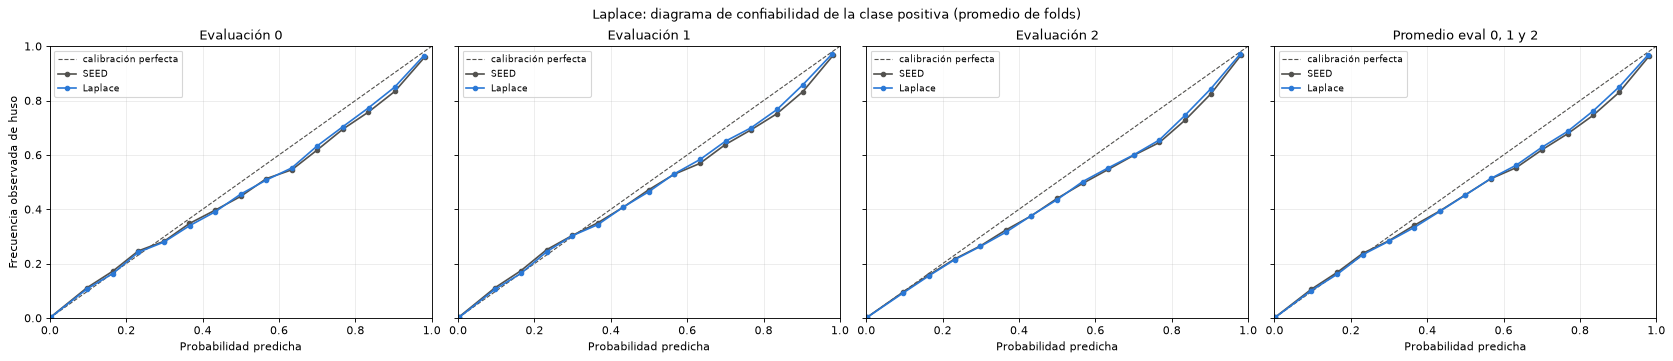

In [2]:
DETECTION = ['F1 evento (%)', 'precisión (%)', 'recall (%)', 'AUROC detección', 'AUPRC detección', 'NLL', 'Brier', 'ECE clase positiva']
display(report.by_evaluation(metrics, DETECTION))
display(metrics.set_index(['evaluación', 'fold'])[DETECTION].round(4))
show(report.plot_reliability(results, METHOD))

## 2. Curvas ROC

Curva promedio de los folds. *Detección*: huso vs fondo con la probabilidad. *Errores*: timesteps mal clasificados vs bien clasificados cerca de eventos, ordenados por cada medida de incertidumbre.

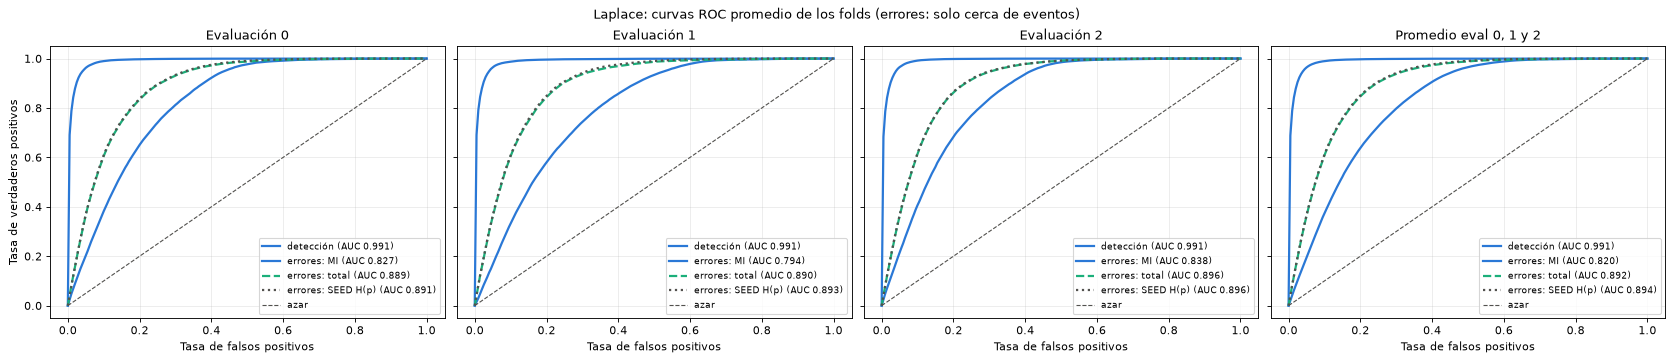

In [3]:
show(report.plot_roc(results, METHOD))

## 3. Descomposición de la incertidumbre

Entropía media en bits, en todo el registro y cerca de eventos, separada en aleatoria y epistémica (MI), con la incertidumbre de SEED como referencia.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
total (registro),0.06639 ± 0.0095,0.07077 ± 0.0072,0.06795 ± 0.0084,0.06837 ± 0.008
aleatoria (registro),0.0634 ± 0.0091,0.06449 ± 0.0062,0.06598 ± 0.0074,0.06462 ± 0.0072
SEED H(p) (registro),0.06025 ± 0.0091,0.05881 ± 0.0089,0.06412 ± 0.006,0.06106 ± 0.0079
MI (registro),0.002988 ± 0.0022,0.006288 ± 0.0055,0.001966 ± 0.0012,0.003747 ± 0.0038
% epistémica (registro),4.485 ± 3,8.586 ± 7.4,2.803 ± 1.3,5.291 ± 5
total (cerca de eventos),0.2401 ± 0.012,0.2464 ± 0.022,0.2442 ± 0.0086,0.2435 ± 0.014
aleatoria (cerca de eventos),0.2309 ± 0.011,0.2333 ± 0.023,0.2372 ± 0.0082,0.2338 ± 0.015
SEED H(p) (cerca de eventos),0.2269 ± 0.01,0.227 ± 0.026,0.2346 ± 0.0083,0.2295 ± 0.016
MI (cerca de eventos),0.009174 ± 0.0049,0.01306 ± 0.0077,0.006994 ± 0.0025,0.009741 ± 0.0057
% epistémica (cerca de eventos),3.79 ± 1.9,5.328 ± 3.3,2.858 ± 1,3.992 ± 2.3


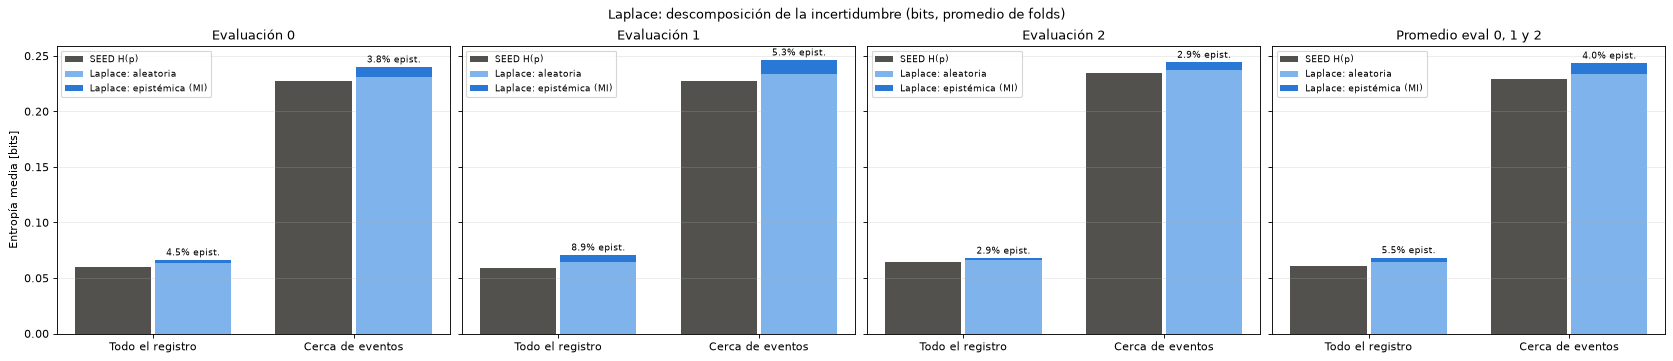

In [4]:
DECOMPOSITION = [c for c in metrics.columns if c.endswith('(registro)') or c.endswith('(cerca de eventos)')]
display(report.by_evaluation(metrics, DECOMPOSITION))
show(report.plot_decomposition(results, METHOD))

## 4. ¿La incertidumbre detecta los errores?

Errores por timestep cerca de eventos: AUROC y AUPRC de cada medida. El AUPRC se compara con la tasa de error (azar).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
AUROC errores: total,0.8894 ± 0.0064,0.8897 ± 0.009,0.8955 ± 0.0023,0.8915 ± 0.0067
AUPRC errores: total,0.4109 ± 0.011,0.4067 ± 0.0082,0.4147 ± 0.0048,0.4108 ± 0.0083
AUROC errores: aleatoria,0.8904 ± 0.0054,0.8918 ± 0.0075,0.8959 ± 0.002,0.8927 ± 0.0056
AUPRC errores: aleatoria,0.4129 ± 0.0055,0.411 ± 0.0094,0.4135 ± 0.0084,0.4125 ± 0.0074
AUROC errores: SEED H(p),0.8912 ± 0.0054,0.8931 ± 0.0072,0.8965 ± 0.002,0.8936 ± 0.0054
AUPRC errores: SEED H(p),0.4127 ± 0.0092,0.4113 ± 0.0074,0.4165 ± 0.0055,0.4135 ± 0.0073
AUROC errores: MI,0.8267 ± 0.034,0.7943 ± 0.062,0.8377 ± 0.017,0.8196 ± 0.043
AUPRC errores: MI,0.2889 ± 0.061,0.2492 ± 0.063,0.2974 ± 0.026,0.2785 ± 0.053
azar errores,0.1048 ± 0.0028,0.1029 ± 0.0044,0.1039 ± 0.0041,0.1039 ± 0.0036


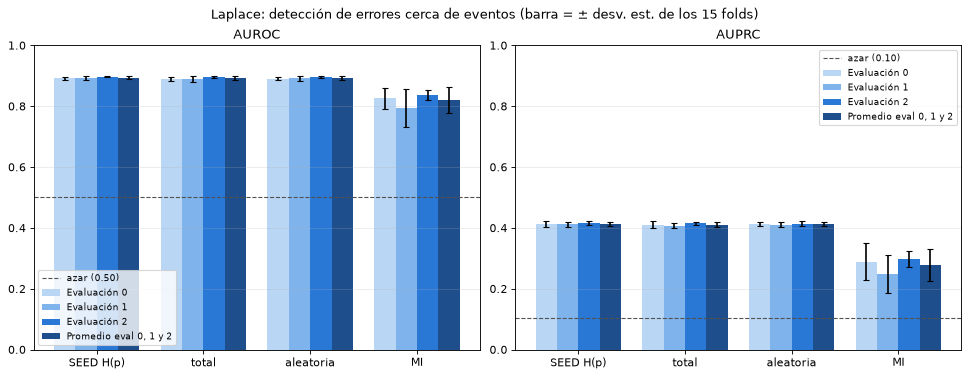

In [5]:
ERRORS = [c for c in metrics.columns if c.startswith('AUROC errores') or c.startswith('AUPRC errores')] + ['azar errores']
display(report.by_evaluation(metrics, ERRORS))
show(report.plot_error_detection(results, METHOD))

## 5. Dónde se concentra la incertidumbre

Entropía media por zona: bordes de los husos (±0.25 s del inicio o fin real), interior del huso y fondo.

Borde del huso
Interior del huso
Fondo


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,6.124 ± 0.34,6.124 ± 0.24,6.124 ± 0.36,6.124 ± 0.3
SEED H(p),0.4373 ± 0.015,0.4373 ± 0.033,0.4466 ± 0.014,0.4404 ± 0.021
aleatoria,0.4402 ± 0.016,0.4422 ± 0.03,0.4487 ± 0.013,0.4437 ± 0.02
MI,0.01763 ± 0.0086,0.02209 ± 0.011,0.0136 ± 0.0046,0.01778 ± 0.0087


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,2.055 ± 0.25,2.055 ± 0.19,2.055 ± 0.2,2.055 ± 0.2
SEED H(p),0.2824 ± 0.076,0.2848 ± 0.057,0.2954 ± 0.066,0.2876 ± 0.062
aleatoria,0.2933 ± 0.077,0.2969 ± 0.057,0.3053 ± 0.065,0.2985 ± 0.062
MI,0.0123 ± 0.0057,0.01516 ± 0.0065,0.01034 ± 0.0034,0.0126 ± 0.0054


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,91.82 ± 0.53,91.82 ± 0.36,91.82 ± 0.55,91.82 ± 0.45
SEED H(p),0.03029 ± 0.011,0.02841 ± 0.0057,0.0336 ± 0.006,0.03076 ± 0.0077
aleatoria,0.03328 ± 0.011,0.03398 ± 0.003,0.03526 ± 0.0074,0.03418 ± 0.0074
MI,0.00181 ± 0.0018,0.005035 ± 0.0052,0.001001 ± 0.00089,0.002615 ± 0.0035


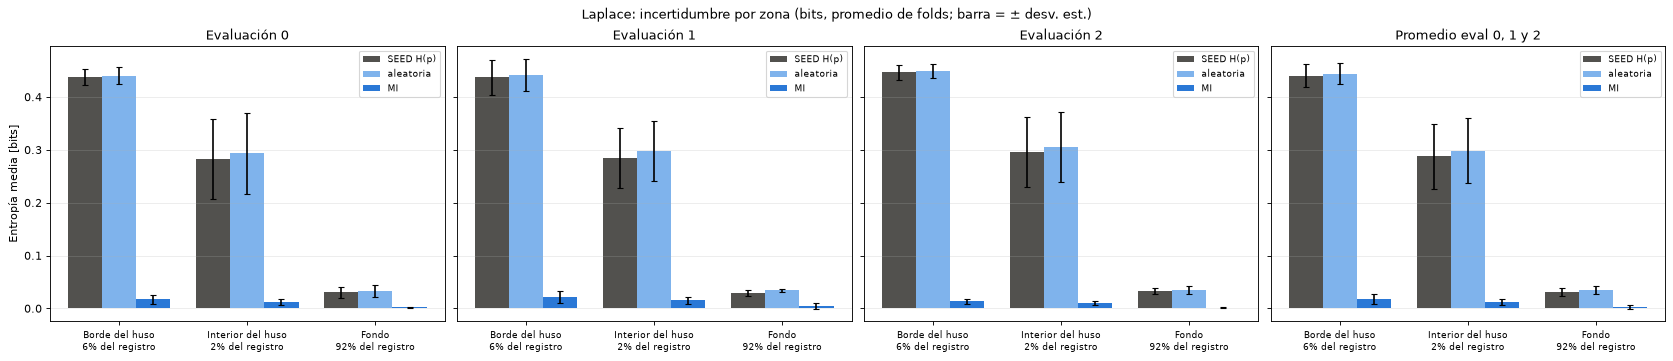

In [6]:
zones = results['zones']
for zone in ['Borde del huso', 'Interior del huso', 'Fondo']:
    print(zone)
    display(report.by_evaluation(zones[zones['zona'] == zone], [c for c in zones.columns if c not in ('evaluación', 'fold', 'zona')]))
show(report.plot_zones(results, METHOD))

## 6. Duración del evento vs incertidumbre

ρ es la correlación de Spearman entre la duración de cada evento predicho y su incertidumbre media (MI; para SEED, su entropía). ρ < 0: los eventos cortos son más inciertos.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
ρ duración-incertidumbre,-0.4698 ± 0.11,-0.4459 ± 0.14,-0.4189 ± 0.078,-0.4448 ± 0.11


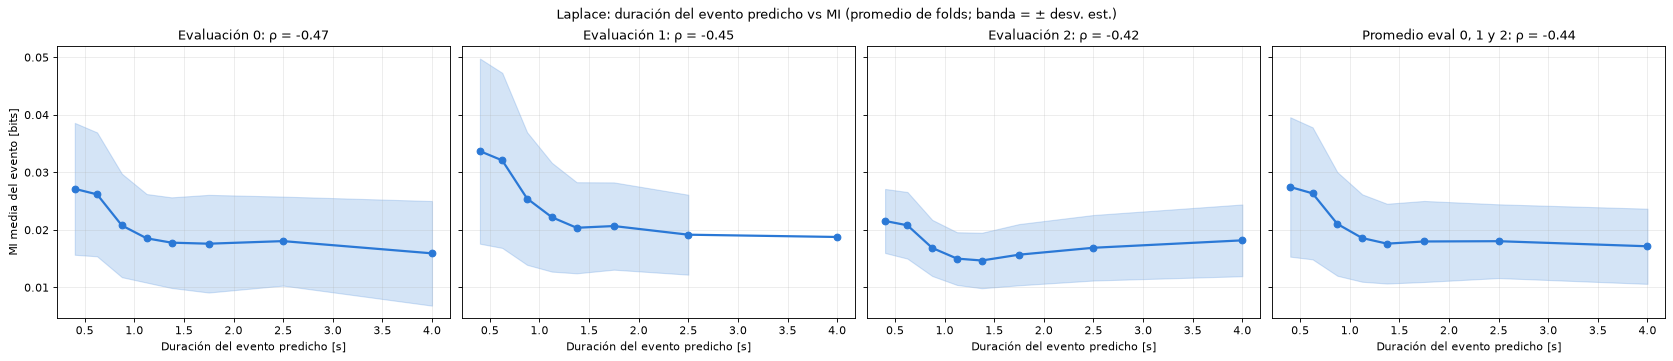

In [7]:
display(report.by_evaluation(metrics, ['ρ duración-incertidumbre']))
show(report.plot_duration(results, METHOD))

## 7. Aciertos, falsos positivos y falsos negativos

- **TP / FP (predicho)**: detecciones correctas y falsas, medidas en el tramo que el modelo predijo.
- **TP / FN (real)**: husos detectados y no detectados, medidos en el tramo real del huso (un FN no tiene tramo predicho). Los pares con IoU < 0.2 cuentan como FN, igual que en el F1.

Primero las medianas de cada medida, luego qué tan bien cada medida separa FP de TP y FN de TP (AUROC y AUPRC con su azar), y al final los gráficos de cajón en percentil dentro del fold, con la línea de azar en 0.5. Comparar la *probabilidad media* entre FN y TP es casi circular (un FN es justamente un tramo con probabilidad baja).

Medianas por tipo de evento
FP vs TP (tramo predicho)
FN vs TP (tramo real)


eval 0                                                                                           eval 1                                                                                           eval 2                      \
              probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std) probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std) probabilidad media incertidumbre total   
grupo                                                                                                                                                                                                                                                    
TP (predicho)             0.8698              0.4418    0.4191          0.0206                          0.0511             0.8697              0.4489    0.4230          0.0235                          0.0553             0.8719              0.4380   
FP (predicho)             0.6292              0.9295    0.9018          0.0228                          0.0804             0.6408              0.9187    0.8896          0.0266                          0.0828             0.6490              0.9072   
TP (real)                 0.8608              0.4039    0.3837          0.0187                          0.0469             0.8584              0.4122    0.3883          0.0217                          0.0515             0.8629              0.4035   
FN (real)                 0.1787              0.6076    0.5973          0.0095                          0.0392             0.1837              0.6404    0.6243          0.0115                          0.0427             0.1938              0.6276   

                                                                        promedio eval 0, 1 y 2                                                                                
              aleatoria epistémica (MI) dispersión entre muestras (std)     probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std)  
grupo                                                                                                                                                                         
TP (predicho)    0.4186          0.0169                          0.0476                 0.8705              0.4423    0.4204          0.0197                          0.0512  
FP (predicho)    0.8805          0.0228                          0.0778                 0.6405              0.9204    0.8913          0.0235                          0.0799  
TP (real)        0.3860          0.0152                          0.0428                 0.8606              0.4070    0.3859          0.0179                          0.0469  
FN (real)        0.6216          0.0065                          0.0339                 0.1848              0.6281    0.6181          0.0089                          0.0385

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1653 ± 0.063,0.1544 ± 0.029,0.1768 ± 0.035,0.1655 ± 0.042
AUROC probabilidad media,0.8551 ± 0.011,0.8451 ± 0.01,0.8473 ± 0.029,0.8492 ± 0.018
AUPRC probabilidad media,0.4804 ± 0.096,0.4561 ± 0.064,0.4962 ± 0.097,0.4776 ± 0.082
AUROC incertidumbre total,0.8552 ± 0.0088,0.8494 ± 0.01,0.8519 ± 0.029,0.8522 ± 0.017
AUPRC incertidumbre total,0.4455 ± 0.13,0.4518 ± 0.065,0.4854 ± 0.11,0.4609 ± 0.1
AUROC aleatoria,0.856 ± 0.0084,0.8497 ± 0.0099,0.8517 ± 0.029,0.8524 ± 0.017
AUPRC aleatoria,0.4551 ± 0.13,0.451 ± 0.065,0.4858 ± 0.11,0.464 ± 0.097
AUROC epistémica (MI),0.6631 ± 0.07,0.6598 ± 0.06,0.6861 ± 0.046,0.6697 ± 0.057
AUPRC epistémica (MI),0.2583 ± 0.13,0.2292 ± 0.057,0.2902 ± 0.073,0.2593 ± 0.088
AUROC dispersión entre muestras (std),0.8107 ± 0.024,0.8038 ± 0.023,0.8211 ± 0.035,0.8119 ± 0.027


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1781 ± 0.064,0.1846 ± 0.031,0.1658 ± 0.029,0.1762 ± 0.042
AUROC probabilidad media,0.9541 ± 0.025,0.9646 ± 0.013,0.9555 ± 0.031,0.9581 ± 0.023
AUPRC probabilidad media,0.9328 ± 0.041,0.9468 ± 0.017,0.9303 ± 0.05,0.9366 ± 0.037
AUROC incertidumbre total,0.5861 ± 0.083,0.6137 ± 0.045,0.623 ± 0.042,0.6076 ± 0.058
AUPRC incertidumbre total,0.2148 ± 0.036,0.2489 ± 0.027,0.2235 ± 0.019,0.2291 ± 0.03
AUROC aleatoria,0.596 ± 0.083,0.6274 ± 0.042,0.6321 ± 0.04,0.6185 ± 0.056
AUPRC aleatoria,0.2225 ± 0.037,0.264 ± 0.034,0.2308 ± 0.018,0.2391 ± 0.034
AUROC epistémica (MI),0.1928 ± 0.063,0.1884 ± 0.056,0.1691 ± 0.065,0.1834 ± 0.058
AUPRC epistémica (MI),0.1081 ± 0.035,0.1123 ± 0.017,0.09953 ± 0.012,0.1066 ± 0.022
AUROC dispersión entre muestras (std),0.376 ± 0.083,0.3848 ± 0.063,0.3744 ± 0.077,0.3784 ± 0.069


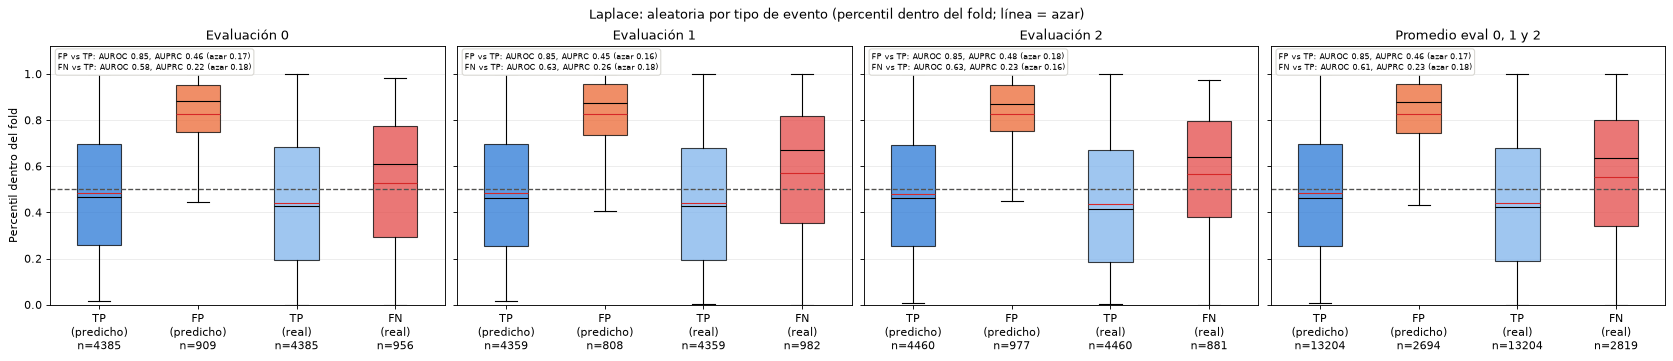

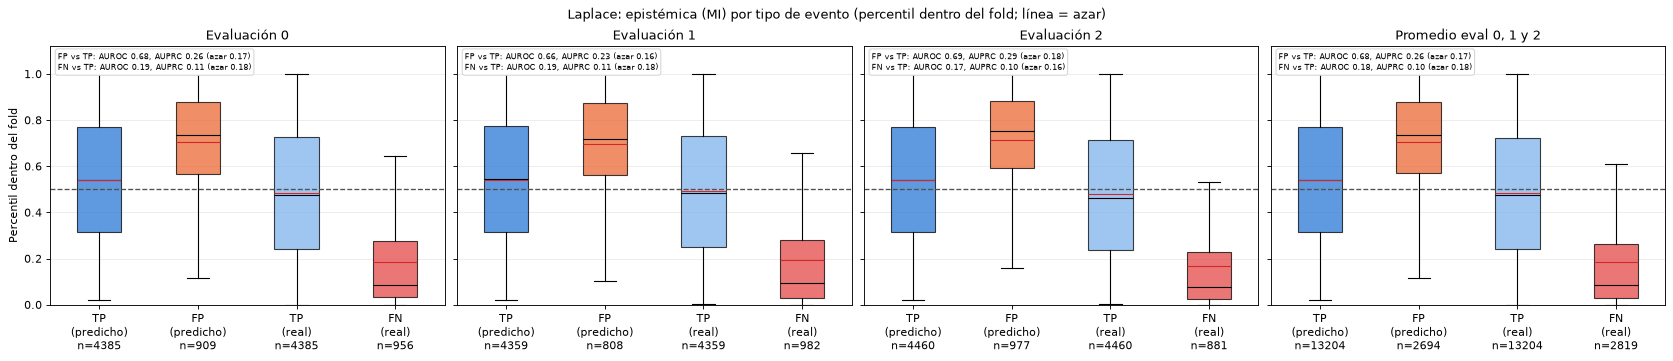

In [8]:
events = results['events']
print('Medianas por tipo de evento')
display(report.event_medians(events))
print('FP vs TP (tramo predicho)')
display(report.event_separation(events, 'TP (predicho)', 'FP (predicho)'))
print('FN vs TP (tramo real)')
display(report.event_separation(events, 'TP (real)', 'FN (real)'))
for figure in report.plot_event_boxes(results, METHOD):
    show(figure)

## 8. Derivar a revisión las detecciones más inciertas

Si se manda a revisión el x% de detecciones con más incertidumbre, ¿qué precisión tiene lo que se acepta automáticamente y qué parte de los falsos positivos se captura?

eval 0
eval 1
eval 2
promedio eval 0, 1 y 2


precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          83.5            83.5                83.5                0.0             0.0                 0.0
5.0                          85.2            84.0                85.2               15.5             6.9                14.7
10.0                         87.1            84.5                87.2               30.3            14.1                31.0
20.0                         91.0            85.9                91.2               57.5            30.5                58.9
30.0                         94.2            87.3                94.3               77.1            45.3                77.5

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          84.6            84.6                84.6                0.0             0.0                 0.0
5.0                          86.3            85.0                86.4               15.5             7.6                16.6
10.0                         88.5            85.7                88.5               33.2            16.1                33.1
20.0                         91.8            86.6                91.8               57.9            30.1                57.6
30.0                         94.4            87.5                94.6               74.5            42.5                75.9

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          82.3            82.3                82.3                0.0             0.0                 0.0
5.0                          84.3            83.2                84.3               15.6             9.5                15.8
10.0                         86.4            83.7                86.4               30.5            17.0                30.9
20.0                         90.1            85.2                90.1               55.1            32.6                54.9
30.0                         93.8            87.0                93.8               75.4            48.0                75.3

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          83.4            83.4                83.4                0.0             0.0                 0.0
5.0                          85.3            84.0                85.3               15.6             8.0                15.7
10.0                         87.3            84.6                87.4               31.4            15.7                31.7
20.0                         91.0            85.9                91.0               56.8            31.1                57.2
30.0                         94.1            87.2                94.2               75.7            45.3                76.2

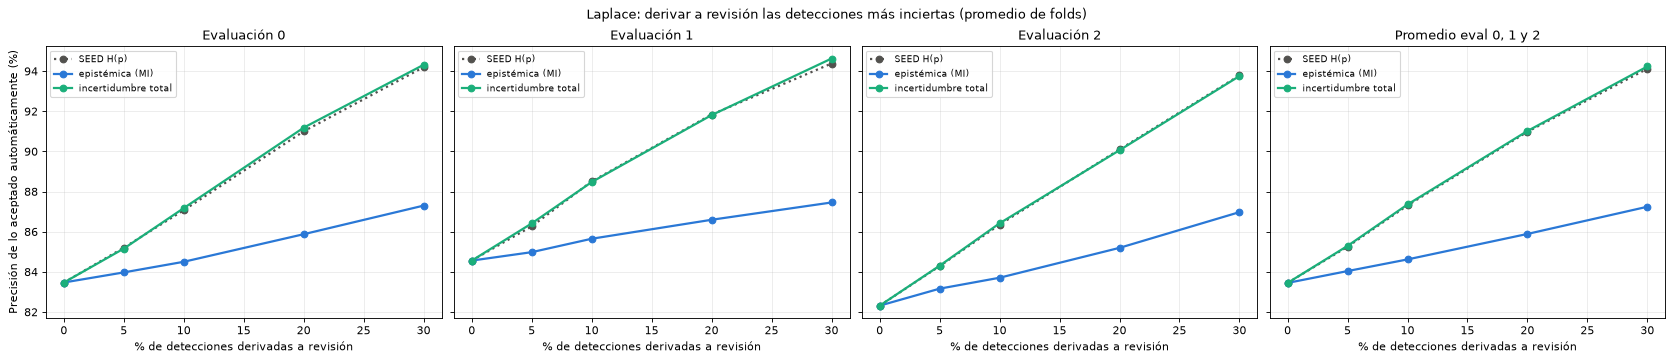

In [9]:
deferral = results['deferral'].dropna(subset=['% derivado'])
for label, part in [(f'eval {e}', deferral[deferral['evaluación'] == e]) for e in report.EVALUATIONS] + [(report.MEAN_SCOPE.lower(), deferral)]:
    print(label)
    display(part.groupby(['medida', '% derivado'])[['precisión aceptado (%)', '% de FP capturados']].mean().round(1).unstack('medida'))
show(report.plot_deferral(results, METHOD))

## 9. Descartar automáticamente las detecciones más inciertas

Sin revisión humana: se eliminan las detecciones con mayor incertidumbre (MI; para SEED, entropía). Los aciertos eliminados pasan a ser falsos negativos. Para que el F1 suba, más de ~58% de lo descartado debe ser FP (con F1 ≈ 83%, el equilibrio es 1 − F1/2).

FP descartados  TP descartados  % FP en lo descartado  cambio F1 (puntos)
medida              % descartado                                                                           
SEED H(p)           0.5                     2.20            3.00                  40.32               -0.08
                    1.0                     6.13            4.53                  56.55               -0.02
                    2.0                    11.40            9.73                  53.00               -0.10
                    5.0                    27.47           25.47                  50.85               -0.37
                    10.0                   55.53           50.53                  51.27               -0.71
                    20.0                  101.20          110.73                  46.67               -2.52
epistémica (MI)     0.5                     1.40            3.80                  26.68               -0.16
                    1.0                     3.53            7.13                  31.91               -0.26
                    2.0                     6.27           14.87                  28.49               -0.59
                    5.0                    15.33           37.60                  27.77               -1.54
                    10.0                   29.80           76.27                  27.07               -3.25
                    20.0                   57.67          154.27                  26.31               -7.03
incertidumbre total 0.5                     2.33            2.87                  43.97               -0.07
                    1.0                     5.47            5.20                  50.46               -0.08
                    2.0                    11.67            9.47                  54.09               -0.08
                    5.0                    27.93           25.00                  51.64               -0.33
                    10.0                   55.93           50.13                  51.69               -0.67
                    20.0                  101.47          110.47                  46.83               -2.48

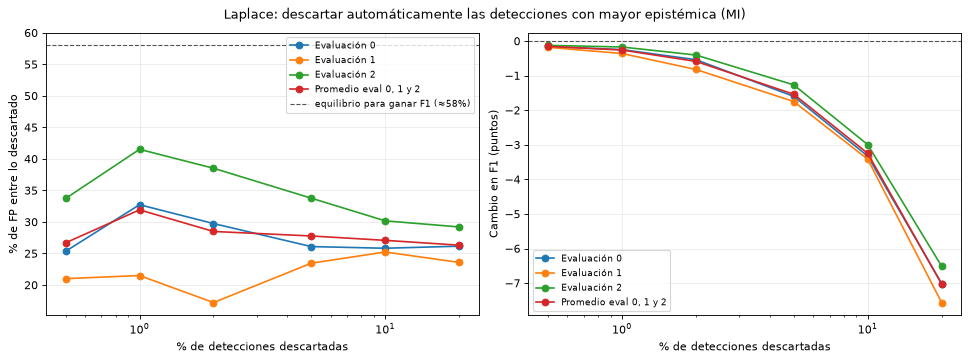

In [10]:
rejection = results['deferral'].dropna(subset=['% descartado'])
display(rejection.groupby(['medida', '% descartado'])[['FP descartados', 'TP descartados', '% FP en lo descartado', 'cambio F1 (puntos)']].mean().round(2))
show(report.plot_rejection(results, METHOD))

## 10. Información del método

Evidencia efectiva (τ y puntos efectivos) y prior elegido en validación, por fold.

In [11]:
info = results['info']
display(info.set_index(['evaluación', 'fold']).round(3))
display(report.by_evaluation(info))

τ (autocorrelación)  puntos efectivos  prior elegido
evaluación fold                                                      
0          0                  28.512         45275.217        193.070
           1                  27.368         47167.281         51.795
           2                  28.629         45090.546          3.728
           3                  28.821         44888.904         51.795
           4                  29.544         43790.608         13.895
1          0                  29.035         44558.182         51.795
           1                  30.960         41694.449          3.728
           2                  29.012         44494.497          3.728
           3                  30.199         42745.816        193.070
           4                  30.978         41762.988         13.895
2          0                  28.349         45635.732         51.795
           1                  27.721         46567.236         13.895
           2                  29.458         43820.735         51.795
           3                  28.826         44781.681         51.795
           4                  30.227         42801.250        193.070

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
τ (autocorrelación),28.57 ± 0.78,30.04 ± 0.98,28.92 ± 0.97,29.18 ± 1.1
puntos efectivos,4.524e+04 ± 1.2e+03,4.305e+04 ± 1.4e+03,4.472e+04 ± 1.5e+03,4.434e+04 ± 1.6e+03
prior elegido,62.86 ± 76,53.24 ± 81,72.47 ± 69,62.86 ± 70


## Hallazgos

Cifras como eval 0 / eval 1 / eval 2 / promedio de las tres (15 folds de test); un solo número es el promedio.

1. **No cambia la detección ni la calibración:** F1 82.4% / 82.9% / 82.8% / 82.7% (igual a SEED), ECE 0.007 / 0.004 / 0.005 / 0.006.
2. **La evidencia corregida es estable** (τ ≈ 28.6 / 30.0 / 28.9 pasos, ~45 / 43 / 45 mil puntos efectivos), **pero el prior elegido varía mucho entre folds** (3.7 a 193): la NLL de validación casi no depende de él.
3. **Su MI es la más débil de los métodos bayesianos:** AUROC de errores 0.827 / 0.794 / 0.838 / 0.820 y AUPRC 0.28 (azar 0.10), por debajo de la incertidumbre de SEED (0.894). La parte epistémica es 3.8% / 5.3% / 2.9% / 4.0% del total.
4. **Más incertidumbre epistémica no significa mejor:** los folds con prior débil tienen más MI (hasta 17%) y la MI que peor ordena los errores (hasta 0.70).
5. **Falsos positivos:** MI con AUROC 0.67 y AUPRC 0.26 (azar 0.17). **Falsos negativos: la MI se invierte** (AUROC 0.18): Laplace duda *menos* justo en los husos que el modelo pierde.
6. **Descartar por MI es contraproducente:** entre las detecciones de mayor MI hay solo ~27% de FP, y el F1 cae hasta 7 puntos.

**Conclusión.** El Laplace de última capa solo duda de 129 parámetros bien determinados; su incertidumbre no aporta información útil sobre SEED.